# Decision trees

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/03-supervised/decision-trees/decision-trees-notebook.ipynb)

Companion notebook for the *Decision trees* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn class that does the same job.

**Data:** the Iris flowers (150 flowers, 4 measurements, 3 species).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import tree
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
MAX_DEPTH = 2

iris = load_iris()
X, y = iris.data, iris.target

## 1. Impurity of a node

With class shares $p_k$ in a node: Gini $G = 1 - \sum_k p_k^2$ and entropy $H = -\sum_k p_k \log_2 p_k$.

In [2]:
def gini(labels: np.ndarray) -> float:
    """Gini impurity of a set of labels."""
    shares = np.bincount(labels) / len(labels)      # p_k
    return 1 - np.sum(shares**2)


def entropy(labels: np.ndarray) -> float:
    """Entropy in bits of a set of labels."""
    shares = np.bincount(labels) / len(labels)
    shares = shares[shares > 0]
    return -np.sum(shares * np.log2(shares))


print(f"all 150 flowers: Gini {gini(y):.3f}, entropy {entropy(y):.3f}")

all 150 flowers: Gini 0.667, entropy 1.585


In [3]:
stump = tree.DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE).fit(X, y)
print("same Gini at the root:", np.isclose(gini(y), stump.tree_.impurity[0]))

same Gini at the root: True


## 2. The best first split

Try every feature and every threshold between two sorted values. Score a split by the
weighted Gini of the two sides, $\frac{n_L}{n}G_L + \frac{n_R}{n}G_R$, and keep the lowest.

In [4]:
def best_split(X: np.ndarray, y: np.ndarray) -> tuple:
    """Lowest weighted Gini over all features and thresholds: (score, feature, threshold)."""
    best = (np.inf, None, None)
    for feature in range(X.shape[1]):
        values = np.unique(X[:, feature])
        midpoints = (values[:-1] + values[1:]) / 2
        for threshold in midpoints:
            left = X[:, feature] <= threshold
            right = ~left
            share_left = left.mean()                    # n_L / n
            share_right = right.mean()                  # n_R / n
            score = share_left * gini(y[left]) + share_right * gini(y[right])
            if score < best[0]:
                best = (score, feature, threshold)
    return best


best_score, best_feature, best_threshold = best_split(X, y)
best_name = iris.feature_names[best_feature]
print(f"by hand: {best_name} <= {best_threshold:.2f}, weighted Gini {best_score:.3f}")

by hand: petal length (cm) <= 2.45, weighted Gini 0.333


In [5]:
left, right = stump.tree_.children_left[0], stump.tree_.children_right[0]
node_sizes = stump.tree_.n_node_samples
node_gini = stump.tree_.impurity
weighted_left = node_sizes[left] / node_sizes[0] * node_gini[left]
weighted_right = node_sizes[right] / node_sizes[0] * node_gini[right]
library_score = weighted_left + weighted_right
library_feature = iris.feature_names[stump.tree_.feature[0]]
print(f"scikit-learn: {library_feature} <= {stump.tree_.threshold[0]:.2f}")
print("same weighted Gini:", np.isclose(best_score, library_score))

scikit-learn: petal length (cm) <= 2.45
same weighted Gini: True


Petal length and petal width both separate setosa perfectly, so the two may pick different
features with the same score.

## 3. Growing the tree

Repeating the best split on each side builds the tree, until a node is pure or reaches `max_depth`.
A leaf predicts the majority class. Each node is stored as `(feature, threshold, left, right)`
and each leaf as a class label. The tree is kept at depth 2: deeper down, two splits can tie and
scikit-learn breaks ties at random, so the two trees may differ there.

In [6]:
class DecisionTreeClassifier:
    """Classification tree grown with recursive Gini splits."""

    def __init__(self, max_depth: int = 3):
        self.max_depth = max_depth

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.tree_ = self._grow(X, y, depth=0)
        return self

    def _grow(self, X, y, depth):
        if depth == self.max_depth or gini(y) == 0:
            return np.bincount(y).argmax()
        _, feature, threshold = best_split(X, y)
        left = X[:, feature] <= threshold
        right = ~left
        left_branch = self._grow(X[left], y[left], depth + 1)
        right_branch = self._grow(X[right], y[right], depth + 1)
        return (feature, threshold, left_branch, right_branch)

    def _predict_one(self, x):
        node = self.tree_
        while isinstance(node, tuple):
            feature, threshold, left, right = node
            node = left if x[feature] <= threshold else right
        return node

    def predict(self, X):
        return np.array([self._predict_one(x) for x in X])

    def score(self, X, y):
        return np.mean(self.predict(X) == y)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)
by_hand = DecisionTreeClassifier(max_depth=MAX_DEPTH).fit(X_train, y_train)

same predictions: True
test accuracy: by hand 0.889, scikit-learn 0.889


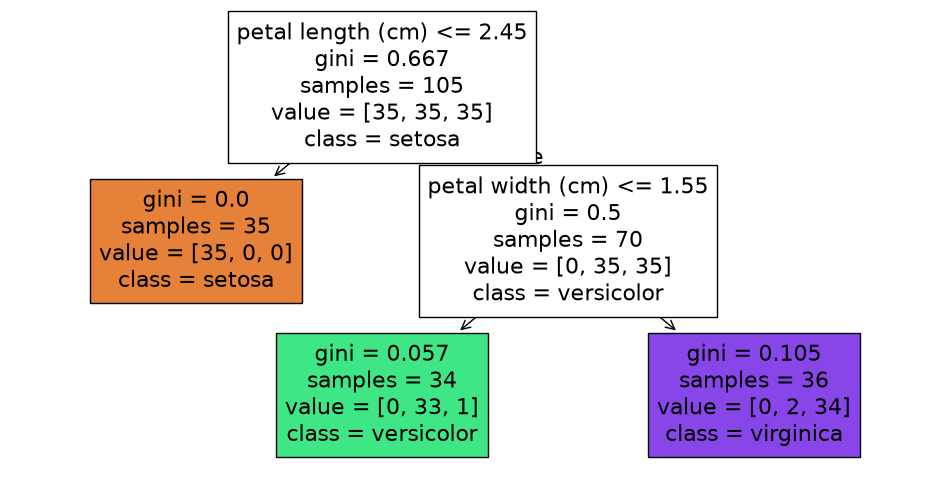

In [7]:
model = tree.DecisionTreeClassifier(max_depth=MAX_DEPTH, random_state=RANDOM_STATE).fit(X_train, y_train)
print("same predictions:", np.array_equal(by_hand.predict(X_test), model.predict(X_test)))
accuracy_by_hand = by_hand.score(X_test, y_test)
accuracy_library = model.score(X_test, y_test)
print(f"test accuracy: by hand {accuracy_by_hand:.3f}, scikit-learn {accuracy_library:.3f}")

plt.figure(figsize=(12, 6))
tree.plot_tree(model, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()

## Exercises

1. Use entropy instead of Gini in section 2 and compare with `tree.DecisionTreeClassifier(criterion="entropy")`.
2. Train trees with `max_depth` from 1 to 8 (by hand and with scikit-learn) and plot training and test accuracy.
3. Print `by_hand.tree_` from section 3 and find the same splits in the scikit-learn plot.